# 01. 分析目的・データ概要

## 1. 分析の目的

本分析では、製造ラインA・B・Cから取得した稼働データを対象に、温度・圧力・振動の推移や特徴を分析する。

データ分析手法の検証を目的として、Pythonで生成した架空の製造ライン稼働データを使用する。各ラインの特性や時間的な変動、異常値候補を意図的に設定している。

各ラインの稼働状況を比較するとともに、センサー値の変動や異常値候補を確認し、設備の状態把握や異常の早期発見につながる情報を抽出することを目的とする。

## 2. データ概要

本分析で使用するデータの概要は以下のとおり。

| 項目 | 内容 |
|:---|:---|
| データ形式 | CSV |
| 対象 | 製造ラインA・B・C |
| 日時 | datetime |
| 測定項目 | temperature, pressure, vibration |
| データ間隔 | 1分間隔 |
| データ期間 | 7日間 |

## 3. データ項目

| 項目名 | 内容 |
|:---|:---|
| datetime | データ取得日時 |
| line | 製造ライン（A・B・C） |
| temperature | 温度 |
| pressure | 圧力 |
| vibration | 振動値 |

# 02. ライブラリの読み込み

本分析で使用するライブラリを読み込む。

In [1]:
# ファイル・ディレクトリ操作
from pathlib import Path

# データ操作・加工
import pandas as pd
import numpy as np

# グラフ作成
import matplotlib.pyplot as plt
import seaborn as sns

# グラフの表示設定
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.family"] = "Noto Sans CJK JP"

# 03. CSVデータの読み込み

製造ラインの稼働データをCSVファイルから読み込む。

日時データは、後続の時系列分析で使用するため、datetime型として読み込む。

In [2]:
# CSVのファイルパスを設定
csv_path = Path("production_data.csv")

# CSVファイルの読み込み
df = pd.read_csv(
    csv_path,
    parse_dates=["datetime"]
)

# データの先頭5行を表示
df.head()

,datetime,line,temperature,pressure,vibration
0,2026-01-01 00:00:00,A,76.241785,309.243315,2.069229
1,2026-01-01 00:00:00,B,63.507404,287.163106,2.043265
2,2026-01-01 00:00:00,C,71.315662,289.474878,1.739436
3,2026-01-01 00:01:00,A,74.658703,293.461787,1.844691
4,2026-01-01 00:01:00,B,64.864993,288.188077,2.157173


# 04. データの基本確認

読み込んだデータの構造や内容を確認する。

主に以下の項目を確認する。

- データの行数・列数
- データの先頭・末尾
- 各列のデータ型
- 欠損値の有無
- 重複レコードの有無
- データの対象期間

In [3]:
# データの行数・列数
df.shape

(30240, 5)

In [4]:
# 先頭5行
df.head()

,datetime,line,temperature,pressure,vibration
0,2026-01-01 00:00:00,A,76.241785,309.243315,2.069229
1,2026-01-01 00:00:00,B,63.507404,287.163106,2.043265
2,2026-01-01 00:00:00,C,71.315662,289.474878,1.739436
3,2026-01-01 00:01:00,A,74.658703,293.461787,1.844691
4,2026-01-01 00:01:00,B,64.864993,288.188077,2.157173


In [5]:
# 末尾5行
df.tail()

,datetime,line,temperature,pressure,vibration
30235,2026-01-07 23:58:00,B,66.247028,290.756939,2.166258
30236,2026-01-07 23:58:00,C,71.562518,304.094556,2.800267
30237,2026-01-07 23:59:00,A,72.396154,299.476767,2.184303
30238,2026-01-07 23:59:00,B,65.166600,300.225005,2.447001
30239,2026-01-07 23:59:00,C,71.037781,295.602320,2.340140


In [6]:
# 列名を確認
df.columns

Index(['datetime', 'line', 'temperature', 'pressure', 'vibration'], dtype='str')

In [7]:
# データ型と非欠損データ数を確認
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30240 entries, 0 to 30239
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   datetime     30240 non-null  datetime64[us]
 1   line         30240 non-null  str           
 2   temperature  30240 non-null  float64       
 3   pressure     30240 non-null  float64       
 4   vibration    30240 non-null  float64       
dtypes: datetime64[us](1), float64(3), str(1)
memory usage: 1.2 MB


In [8]:
# 各列の欠損値の数
df.isnull().sum()

datetime       0
line           0
temperature    0
pressure       0
vibration      0
dtype: int64

In [9]:
# 重複している行数
df.duplicated().sum()

np.int64(0)

In [10]:
# データの開始日時と終了日時
print("開始日時：", df["datetime"].min())
print("終了日時：", df["datetime"].max())

開始日時： 2026-01-01 00:00:00
終了日時： 2026-01-07 23:59:00


# 05. データクレンジング

分析に使用するデータの品質を確認し、必要に応じて修正・加工を行う。

主に以下の項目を確認する。

- 欠損値の有無
- 重複データの有無
- データ型の妥当性
- 数値データの値の妥当性
- 日時・製造ラインの順序

なお、温度・圧力・振動の極端な値については、異常値候補である可能性もあるため、この段階では削除せず、後続の分析で確認する。

In [11]:
# 数値データの最小値・最大値を確認
df[["temperature", "pressure", "vibration"]].agg(
    ["min", "max"]
)

,temperature,pressure,vibration
min,59.957251,268.523045,-0.241586
max,93.754158,353.683561,7.761628


In [12]:
# 同じ日時・同じラインの重複を確認
df.duplicated(
    subset=["datetime", "line"]
).sum()

np.int64(0)

In [13]:
# 日時・ラインの順番で並び替え
df = df.sort_values(
    ["datetime", "line"]
).reset_index(drop=True)

# 06. 基本統計量

温度・圧力・振動の基本統計量を算出し、データ全体の分布や特徴を把握する。

主に以下の統計量を確認する。

- 平均値（mean）
- 標準偏差（std）
- 最小値（min）
- 四分位数（25%、50%、75%）
- 最大値（max）

また、製造ラインごとの基本統計量を比較し、各ラインの測定値の傾向やばらつきの違いを確認する。

In [14]:
# 数値データの基本統計量
df[["temperature", "pressure", "vibration"]].describe()

,temperature,pressure,vibration
count,30240.000000,30240.000000,30240.000000
mean,70.006766,295.030811,2.236741
std,4.586153,6.508032,0.543798
min,59.957251,268.523045,-0.241586
25%,65.744473,290.488659,1.934731
50%,69.873554,295.038205,2.143406
75%,73.606213,299.549813,2.420363
max,93.754158,353.683561,7.761628


In [15]:
# 製造ラインごとの温度の基本統計量
df.groupby("line")["temperature"].describe()

,count,mean,std,min,25%,50%,75%,max
line,,,,,,,,
A,10080.0,75.009494,2.640451,64.217703,73.254419,74.996484,76.750563,93.754158
B,10080.0,64.991924,1.220602,59.957251,64.162228,64.986766,65.831256,69.493878
C,10080.0,70.018879,2.111792,62.950464,68.590569,70.012656,71.459160,77.942622


In [16]:
# 製造ラインごとの圧力の基本統計量
df.groupby("line")["pressure"].describe()

,count,mean,std,min,25%,50%,75%,max
line,,,,,,,,
A,10080.0,300.063792,5.018137,280.718123,296.683968,300.073375,303.472681,322.395421
B,10080.0,290.034690,5.002416,268.523045,286.677401,290.036519,293.437505,307.682658
C,10080.0,294.993953,5.154370,272.685157,291.627438,294.949776,298.353141,353.683561


In [17]:
# 製造ラインごとの振動の基本統計量
df.groupby("line")["vibration"].describe()

,count,mean,std,min,25%,50%,75%,max
line,,,,,,,,
A,10080.0,1.997712,0.197967,1.268983,1.860489,1.999405,2.133302,2.738325
B,10080.0,2.200933,0.252253,1.160567,2.031553,2.203682,2.372612,3.136345
C,10080.0,2.511578,0.806487,-0.241586,1.979798,2.505507,3.040233,7.761628


In [18]:
# 製造ラインごとの平均値と中央値
df.groupby("line")[
    ["temperature", "pressure", "vibration"]
].agg(["mean", "median"])

temperature               pressure             vibration          
            mean     median        mean      median      mean    median
line                                                                   
A      75.009494  74.996484  300.063792  300.073375  1.997712  1.999405
B      64.991924  64.986766  290.034690  290.036519  2.200933  2.203682
C      70.018879  70.012656  294.993953  294.949776  2.511578  2.505507

# 07. 時系列分析

温度・圧力・振動の時間的な変化を可視化し、製造ラインごとの推移や特徴を確認する。

主に以下の項目を分析する。

- 温度の時間的な変化
- 圧力の時間的な変化
- 振動の時間的な変化

各製造ラインの測定値を時系列グラフで比較し、周期的な変動や一時的な急上昇などの特徴を確認する。

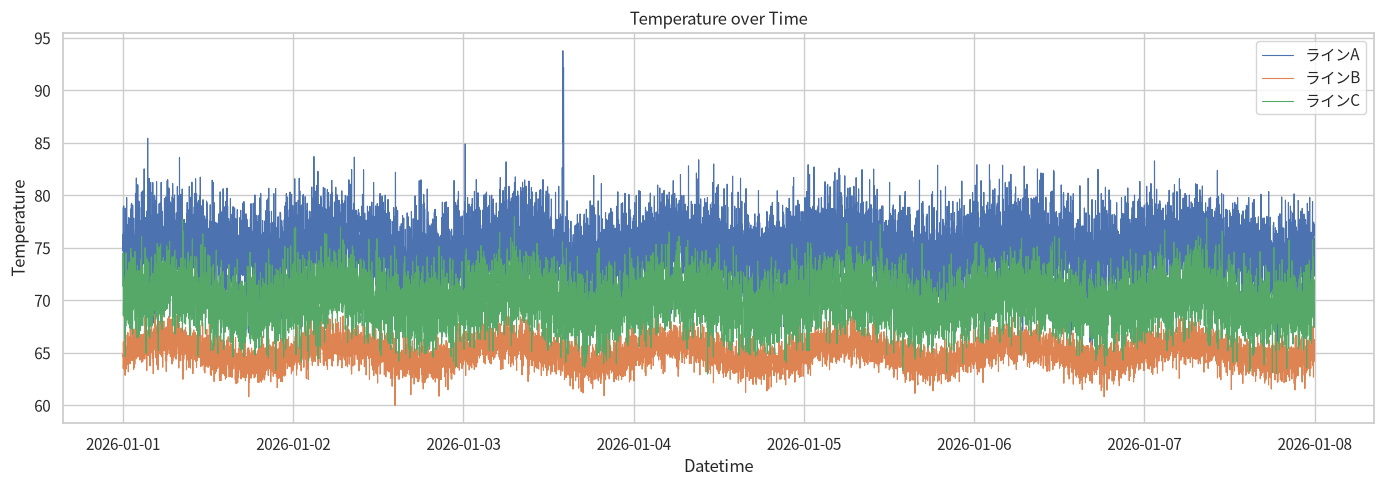

In [19]:
# 温度の時系列グラフ
plt.figure(figsize=(14, 5))

for line in ["A", "B", "C"]:
    df_line = df[df["line"] == line]

    plt.plot(
        df_line["datetime"],
        df_line["temperature"],
        label=f"ライン{line}",
        linewidth=0.8
    )

plt.title("Temperature over Time")
plt.xlabel("Datetime")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

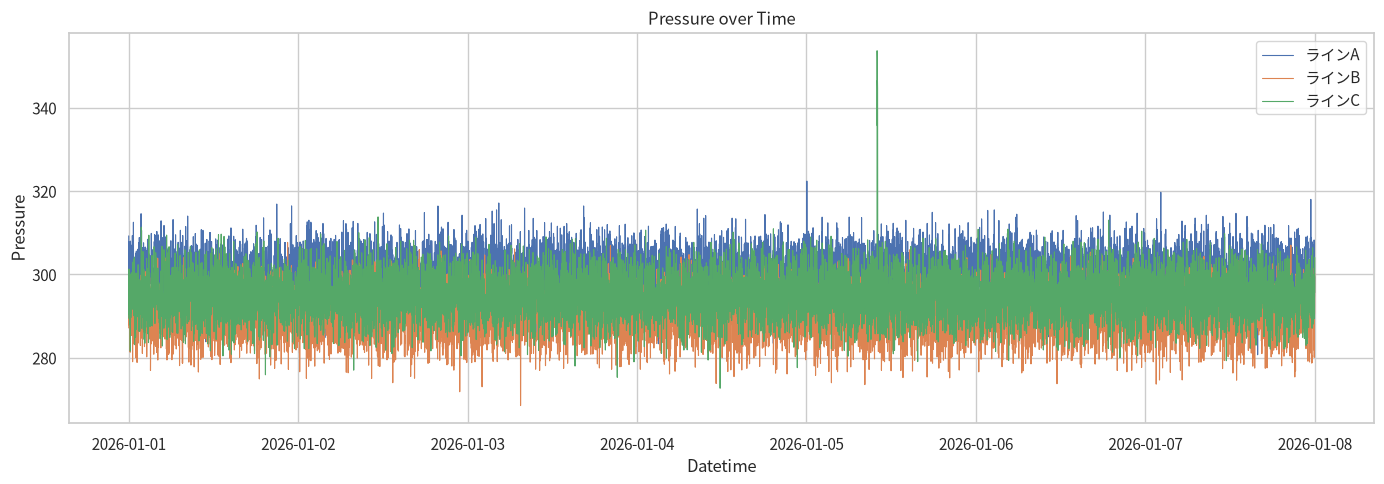

In [20]:
# 圧力の時系列グラフ
plt.figure(figsize=(14, 5))

for line in ["A", "B", "C"]:
    df_line = df[df["line"] == line]

    plt.plot(
        df_line["datetime"],
        df_line["pressure"],
        label=f"ライン{line}",
        linewidth=0.8
    )

plt.title("Pressure over Time")
plt.xlabel("Datetime")
plt.ylabel("Pressure")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

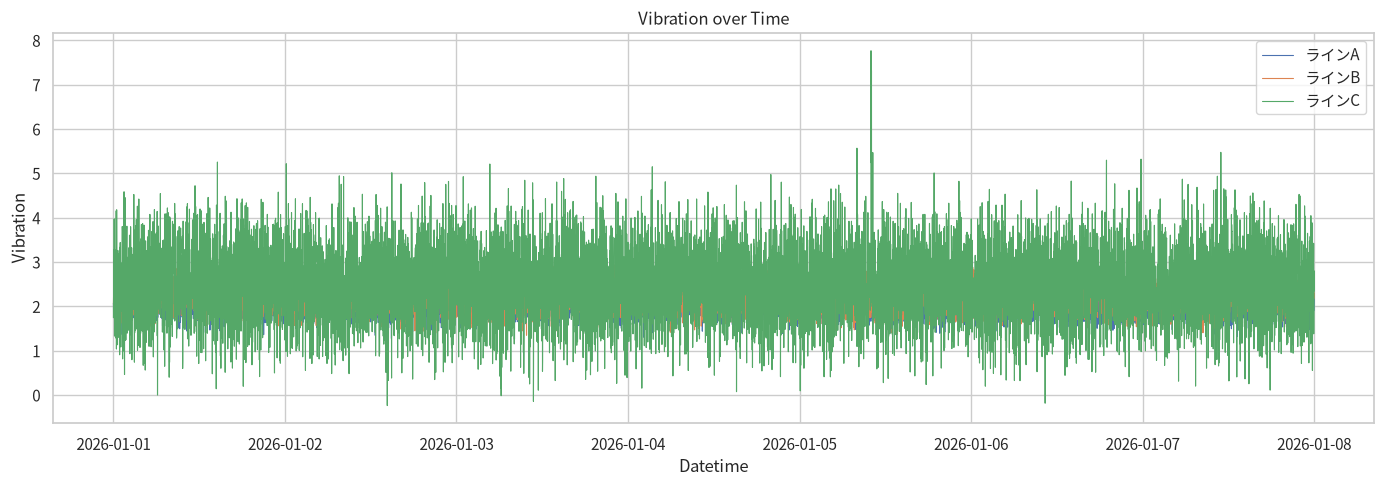

In [21]:
# 振動の時系列グラフ
plt.figure(figsize=(14, 5))

for line in ["A", "B", "C"]:
    df_line = df[df["line"] == line]

    plt.plot(
        df_line["datetime"],
        df_line["vibration"],
        label=f"ライン{line}",
        linewidth=0.8
    )

plt.title("Vibration over Time")
plt.xlabel("Datetime")
plt.ylabel("Vibration")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 08. 相関分析

温度・圧力・振動の各測定項目間の相関関係を分析する。

相関係数を算出し、測定項目間の関連性の強さや方向を確認する。

また、相関行列をヒートマップで可視化し、各測定項目間の相関関係を把握する。

製造ラインごとの相関関係も比較し、ラインによる特徴の違いを確認する。

In [22]:
# 測定項目間の相関係数
corr = df[
    ["temperature", "pressure", "vibration"]
].corr()

corr

,temperature,pressure,vibration
temperature,1.000000,0.562311,-0.133416
pressure,0.562311,1.000000,-0.086902
vibration,-0.133416,-0.086902,1.000000


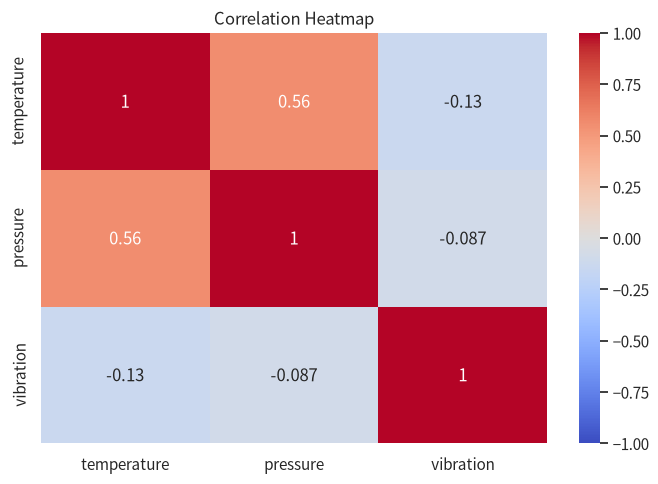

In [23]:
# 相関行列のヒートマップ
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [24]:
# ラインAの相関係数
corr_A = df[df["line"] == "A"][
    ["temperature", "pressure", "vibration"]
].corr()

corr_A

,temperature,pressure,vibration
temperature,1.000000,-0.005628,0.001336
pressure,-0.005628,1.000000,0.004615
vibration,0.001336,0.004615,1.000000


In [25]:
# ラインBの相関係数
corr_B = df[df["line"] == "B"][
    ["temperature", "pressure", "vibration"]
].corr()

corr_B

,temperature,pressure,vibration
temperature,1.000000,0.004975,-0.005589
pressure,0.004975,1.000000,0.003329
vibration,-0.005589,0.003329,1.000000


In [26]:
# ラインCの相関係数
corr_C = df[df["line"] == "C"][
    ["temperature", "pressure", "vibration"]
].corr()

corr_C

,temperature,pressure,vibration
temperature,1.000000,0.014627,0.009251
pressure,0.014627,1.000000,0.024742
vibration,0.009251,0.024742,1.000000


# 09. 異常値候補の検出

温度・圧力・振動の測定値から、通常の変動範囲を大きく外れるデータを検出する。

今回は、四分位範囲（IQR）を用いた方法で異常値候補を抽出する。

主に以下の項目を確認する。

- 温度の異常値候補
- 圧力の異常値候補
- 振動の異常値候補

検出されたデータについて、発生日時や製造ラインを確認し、時系列分析の結果と照らし合わせながら特徴を把握する。

なお、統計的に異常値と判定されたデータが、必ずしも設備の故障や異常を意味するわけではないため、異常値候補として扱う。

In [27]:
# ==========================================
# 1. 異常値候補の検出
# ==========================================

# 対象となる測定項目
measurement_cols = [
    "temperature",
    "pressure",
    "vibration"
]

# 異常値候補を格納するリスト
outlier_list = []

# 製造ラインごとに処理
for line, group in df.groupby("line"):

    # 測定項目ごとに処理
    for col in measurement_cols:

        # 四分位数と四分位範囲を計算
        q1 = group[col].quantile(0.25)
        q3 = group[col].quantile(0.75)
        iqr = q3 - q1

        # 異常値候補の判定基準
        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        # 判定基準から外れるデータを抽出
        mask = (
            (group[col] < lower_limit) |
            (group[col] > upper_limit)
        )

        # 異常値候補を保存
        if mask.any():
            result = group.loc[
                mask,
                ["datetime", "line", col]
            ].copy()

            result = result.rename(
                columns={col: "value"}
            )

            result["measurement"] = col
            result["lower_limit"] = lower_limit
            result["upper_limit"] = upper_limit

            outlier_list.append(result)


# ==========================================
# 2. 検出結果をまとめる
# ==========================================

if outlier_list:
    outliers = pd.concat(
        outlier_list,
        ignore_index=True
    )

    # 日時順に並び替え
    outliers = outliers.sort_values(
        ["datetime", "line"]
    ).reset_index(drop=True)

    # 検出結果を表示
    display(outliers.head(20))

else:
    print("異常値候補は検出されませんでした。")

,datetime,line,value,measurement,lower_limit,upper_limit
0,2026-01-01 00:10:00,B,1.471153,vibration,1.519965,2.884200
1,2026-01-01 00:21:00,B,2.942734,vibration,1.519965,2.884200
2,2026-01-01 00:47:00,A,286.387729,pressure,286.500898,313.655751
3,2026-01-01 01:13:00,A,1.360147,vibration,1.451270,2.542522
4,2026-01-01 01:45:00,A,314.570546,pressure,286.500898,313.655751
5,2026-01-01 01:47:00,C,311.328791,pressure,281.538883,308.441696
6,2026-01-01 02:17:00,A,286.297868,pressure,286.500898,313.655751
7,2026-01-01 02:37:00,C,76.068358,temperature,64.287681,75.762048
8,2026-01-01 02:51:00,C,309.414987,pressure,281.538883,308.441696
9,2026-01-01 02:59:00,A,82.504438,temperature,68.010204,81.994777


In [28]:
# 製造ライン・測定項目ごとの検出件数
outliers.groupby(
    ["line", "measurement"]
).size().unstack(fill_value=0)

measurement,pressure,temperature,vibration
line,,,
A,84,75,50
B,62,59,61
C,65,56,83


In [29]:
# 異常値候補を日時順に確認
display(outliers.head(20))

,datetime,line,value,measurement,lower_limit,upper_limit
0,2026-01-01 00:10:00,B,1.471153,vibration,1.519965,2.884200
1,2026-01-01 00:21:00,B,2.942734,vibration,1.519965,2.884200
2,2026-01-01 00:47:00,A,286.387729,pressure,286.500898,313.655751
3,2026-01-01 01:13:00,A,1.360147,vibration,1.451270,2.542522
4,2026-01-01 01:45:00,A,314.570546,pressure,286.500898,313.655751
5,2026-01-01 01:47:00,C,311.328791,pressure,281.538883,308.441696
6,2026-01-01 02:17:00,A,286.297868,pressure,286.500898,313.655751
7,2026-01-01 02:37:00,C,76.068358,temperature,64.287681,75.762048
8,2026-01-01 02:51:00,C,309.414987,pressure,281.538883,308.441696
9,2026-01-01 02:59:00,A,82.504438,temperature,68.010204,81.994777


# 10. 分析結果のまとめ・考察

これまでの分析結果をもとに、製造ラインごとの特徴や測定値の変動傾向について整理する。

## 1. 製造ラインごとの特徴

- **ラインA**：未作成
- **ラインB**：未作成
- **ラインC**：未作成

## 2. 時系列分析から確認できた特徴

未作成

## 3. 相関分析から確認できた特徴

未作成

## 4. 異常値候補の分析

未作成

## 5. 今後の分析・改善に向けて

未作成